# A relational neuron's four 90° stimuli → `future_field_ring.pdf`, `future_field_inequalities.pdf`

One ring, four two-object stimuli, every pair 90° apart, drawn in the style of the 90°
stimulus panels of [`../figure_2/psth.ipynb`](../figure_2/psth.ipynb).

The objects sit at the four diagonal ring positions, so the chords joining neighbouring
positions are **vertical or horizontal** rather than oblique. Naming those positions
clockwise from the top left, the four chords are the 2×2 crossing of
$\theta \in \{\theta_1, \theta_2\}$ with $\phi \in \{\phi_1, \phi_2\}$:

| chord | stimulus | colour |
|---|---|---|
| left, vertical | $(\theta_1, \phi_1)$ | red |
| top, horizontal | $(\theta_1, \phi_2)$ | blue |
| right, vertical | $(\theta_2, \phi_2)$ | red |
| bottom, horizontal | $(\theta_2, \phi_1)$ | blue |

That layout is what makes the second figure sayable: $\theta_1$ can be compared against
$\theta_2$ **twice**, once in each $\phi$ context, so the pair of inequalities is a
preference that survives a change of context rather than a fact about one stimulus.

Vertical chords are red and horizontal ones blue, decided from each chord's own geometry
rather than from its position in the list — so rotating `CORNERS_DEG` re-colours the chords
correctly instead of leaving a now-oblique one labelled "vertical".


In [1]:
import matplotlib.pyplot as plt

import numpy as np

import common

common.set_style()

FIGSIZE_RING = (1.9, 1.9)
FIGSIZE_EQ = (1.5, 0.8)


# ── The panels ────────────────────────────────────────────────────────────────
# Formerly `proof_lib.py`, inlined: these two figures are drawn nowhere else, and a module
# imported by exactly one notebook is a level of indirection that costs more than it saves.
# The geometry follows `figures/figure_2`'s stimulus schematics — dashed ring, `+` at
# fixation, axes spanning [0, 1] with the radius in axes fractions — so these panels sit
# beside those without re-tuning.

CORNERS_DEG = (135.0, 45.0, 315.0, 225.0)     # clockwise from the top left
LABELS = (r'$\theta_1$', r'$\varphi_2$', r'$\theta_2$', r'$\varphi_1$')

RED = (0.84, 0.0, 0.0)        # the vertical chords ...
BLUE = (0.0, 0.2, 0.71)       # ... and the horizontal ones

RADIUS = 0.38                 # ring radius in axes fractions (0.5 would fill the panel)
# Each label is pushed radially out of its corner by LABEL_PAD, then nudged diagonally so it
# clears the two chords meeting there.
LABEL_PAD = 0.12
LABEL_OFFSETS = ((-0.03, 0.03), (0.03, 0.03), (0.03, -0.03), (-0.03, -0.03))


def _xy(theta_deg, radius=RADIUS):
    """Ring position in the [0, 1] axes square."""
    t = np.radians(theta_deg)
    return 0.5 + radius * np.cos(t), 0.5 + radius * np.sin(t)


def ring_figure(figsize=(1.5, 1.5)):
    """The ring with its four 90° chords, corner circles and labels."""
    fig, ax = plt.subplots(figsize=figsize)

    circ = np.linspace(0, 2 * np.pi, 200)
    ax.plot(0.5 + RADIUS * np.cos(circ), 0.5 + RADIUS * np.sin(circ), ls='--', color='k',
            lw=0.7, alpha=0.35, zorder=1)
    ax.plot(0.5, 0.5, marker='+', color='k', markersize=7, markeredgewidth=1.3, zorder=2)

    pts = [_xy(a) for a in CORNERS_DEG]
    for i, (x0, y0) in enumerate(pts):                 # consecutive corners: the square's sides
        x1, y1 = pts[(i + 1) % len(pts)]
        color = RED if abs(y1 - y0) > abs(x1 - x0) else BLUE
        ax.plot([x0, x1], [y0, y1], color=color, lw=2.2, solid_capstyle='butt', zorder=3)
    for x, y in pts:
        ax.scatter([x], [y], s=70, facecolors='none', edgecolors='k', linewidths=1.2,
                   zorder=4)

    for (x, y), text, (sx, sy) in zip(pts, LABELS, LABEL_OFFSETS):
        dx, dy = x - 0.5, y - 0.5
        norm = np.hypot(dx, dy) or 1.0
        ax.text(x + LABEL_PAD * dx / norm + sx, y + LABEL_PAD * dy / norm + sy, text,
                ha='center', va='center', fontsize=14, zorder=5)

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    fig.tight_layout()          # with the labels in place, so none is cut off
    return fig, ax


#: The two orderings, as (mathtext, colour) pieces so each term keeps its chord's colour.
EQ_LINES = (((r'$R(\theta_1, \varphi_1)$', RED), (r'$>$', 'k'), (r'$R(\theta_2, \varphi_1)$', BLUE)),
            ((r'$R(\theta_1, \varphi_2)$', BLUE), (r'$<$', 'k'), (r'$R(\theta_2, \varphi_2)$', RED)))


def equation_figure(lines=EQ_LINES, figsize=(1.5, 0.8), fontsize=12, linespacing=1.9,
                    piece_gap=0.015):
    """The inequalities, centred, one per row, with **per-term colours**.

    Pieces exist because mathtext colours a whole text artist at once: giving
    `(theta_1, phi_1)` and `(theta_2, phi_1)` different colours means separate artists, laid
    out by measuring each one's rendered width and packing them left to right. The row is
    then shifted so the assembled line is centred — which a single centred artist would have
    given for free, and this has to do by hand.

    Drawn as a figure rather than as notebook markdown so it exports to PDF beside the ring
    and keeps the paper's font; `pdf.fonttype = 42` leaves the symbols editable.
    """
    fig, ax = plt.subplots(figsize=figsize)
    ax.axis('off')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    # A row's height as a fraction of the axes: fontsize is in points, so it is measured
    # against the axes height in points rather than against the data limits.
    ax_h_pt = figsize[1] * 72.0 * ax.get_position().height
    step = fontsize * linespacing / max(ax_h_pt, 1e-9)
    ys = 0.5 + (np.arange(len(lines))[::-1] - (len(lines) - 1) / 2.0) * step

    fig.canvas.draw()                   # a renderer must exist before widths can be read
    renderer = fig.canvas.get_renderer()
    inv = ax.transAxes.inverted()
    for row, y in zip(lines, ys):
        artists = [ax.text(0.0, y, text, color=c, fontsize=fontsize, ha='left', va='center')
                   for text, c in row]
        widths = [a.get_window_extent(renderer=renderer).transformed(inv).width
                  for a in artists]
        x = 0.5 - (sum(widths) + piece_gap * (len(widths) - 1)) / 2.0
        for a, w in zip(artists, widths):
            a.set_x(x)
            x += w + piece_gap
    return fig, ax


## 1. The ring

Fixation cross, dashed stimulus ring, and the four 90° chords. Each object position carries a small circle and its name; vertical chords are red, horizontal ones blue, decided from each chord’s own geometry.

saved future_field_ring.pdf


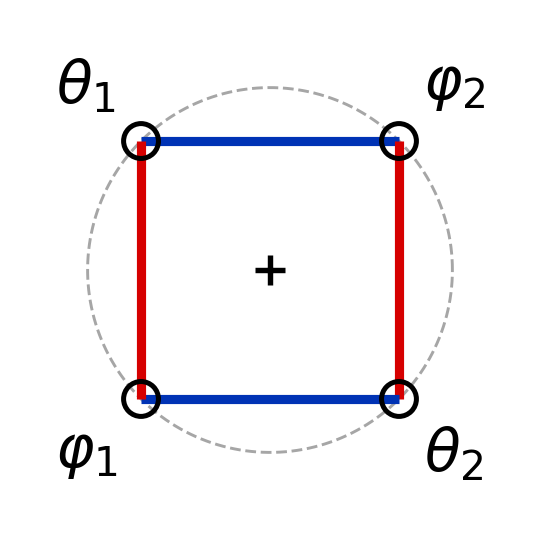

In [2]:
fig, _ = ring_figure(figsize=FIGSIZE_RING)
common.save(fig, 'future_field_ring.pdf')
plt.show()

## 2. The inequalities

The two orderings, each term coloured like the chord it names. Rendered as a figure rather than as markdown so it exports to PDF with the panel above and keeps the paper’s font.

saved future_field_inequalities.pdf


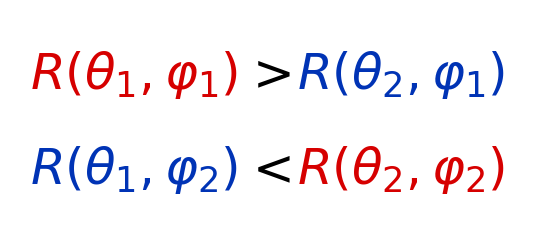

In [3]:
fig, _ = equation_figure(figsize=FIGSIZE_EQ)
common.save(fig, 'future_field_inequalities.pdf')
plt.show()